# 01 · Solutions

**Question.** What does a case's solution look like: its decoded field in both forms against the exact solution, the matrices behind it, and its metrics from every stage?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = (
    "p2_reproduction",
    "p3_pillar1",
    "p4_stateprep",
    "p4_t1",
    "p4_t3",
    "p5_build",
    "p5_encode",
    "p5_stateprep",
    "p5_t1",
    "p5_t3",
    "p5_encoders",
    "p6_build",
    "p6_encode",
    "p6_stateprep",
    "p6_t3",
    "p6_t1",
    "p7_build",
    "p7_encode",
    "p7_stateprep",
    "p7_t3",
    "p7_lift",
)
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p2_reproduction: 327 records, 327 ok
p3_pillar1: 104 records, 104 ok
p4_stateprep: 231 records, 231 ok
p4_t1: 96 records, 91 ok
p4_t3: 133 records, 133 ok
p5_build: 224 records, 224 ok
p5_encode: 60 records, 60 ok
p5_stateprep: 338 records, 338 ok
p5_t1: 90 records, 84 ok
p5_t3: 192 records, 192 ok
p5_encoders: 14 records, 14 ok
p6_build: 374 records, 374 ok
p6_encode: 72 records, 72 ok
p6_stateprep: 162 records, 162 ok
p6_t3: 140 records, 140 ok
p6_t1: 16 records, 16 ok
p7_build: 250 records, 250 ok
p7_encode: 28 records, 28 ok
p7_stateprep: 32 records, 32 ok
p7_t3: 64 records, 64 ok
p7_lift: 45 records, 45 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.solutions import Catalogue

catalogue = Catalogue.read(results, CAMPAIGNS)
coverage = catalogue.coverage()
columns = [
    ("family", "family", ""),
    ("problems", "problems", "d"),
    ("cases", "cases", "d"),
    ("with_field", "with a field", "d"),
    ("prepared", "preparations that keep their field", "d"),
    ("earlier", "preparations that kept none", "d"),
]
earlier = sum(entry["earlier"] for entry in coverage)
lines = [
    f"{sum(entry['cases'] for entry in coverage)} cases of "
    f"{sum(entry['problems'] for entry in coverage)} problems, by family:",
    "",
    plotting.markdown_table(coverage, columns),
]
if earlier:
    lines.append(
        f"\n{earlier} of the preparations chosen come from records that kept no field: their "
        "cases draw the ground state's field instead."
    )
display(Markdown("\n".join(lines)))

556 cases of 56 problems, by family:

| family | problems | cases | with a field | preparations that keep their field | preparations that kept none |
|---|---|---|---|---|---|
| curve | 15 | 258 | 251 | 242 | 4 |
| fields | 1 | 8 | 8 | 16 | 0 |
| surface | 3 | 30 | 30 | 33 | 0 |
| burgers | 15 | 131 | 131 | 66 | 0 |
| vorticity | 22 | 129 | 125 | 32 | 0 |

4 of the preparations chosen come from records that kept no field: their cases draw the ground state's field instead.

**The viewer.** Choose a problem, then its case: n and the Carleman order K, and for a panel of the
paper whether as printed. A time-dependent case has a slider through its window. Each case shows its
fields in both forms against the reference, the spy plots of R and H with their blocks marked, and
its metrics from every stage.

In [3]:
plotting.viewer(catalogue)

**A gallery**, one case of each family: the case with the most fields to draw. The ground
state's field is what an exact preparation gives; a prepared state's (T2 dashed, T1 dotted) is
drawn where its record keeps it.

### R4b, n = 4
Fig. 5b: f'' + 4f' + 4f = e^{-2x}, BC {f(0), f'(0)} = {-1, 1}, DC_I f(x_z = -0.73) = 0, p = 3

| stage | form | run key |
|---|---|---|
| build | standard | `build/R4b/standard/n4` |
| build | descriptor | `build/R4b/descriptor/n4` |
| encoding | standard | `encode/R4b/standard/n4/verify=probe` |
| encoding | descriptor | `encode/R4b/descriptor/n4/verify=probe` |
| T2 | standard | `stateprep/R4b/standard/n4/T2/filter=minimax` |
| T2 | descriptor | `stateprep/R4b/descriptor/n4/T2/filter=minimax` |
| T3 | standard | `stateprep/R4b/standard/n4/T3/filter=minimax` |
| T3 | descriptor | `stateprep/R4b/descriptor/n4/T3/filter=minimax` |

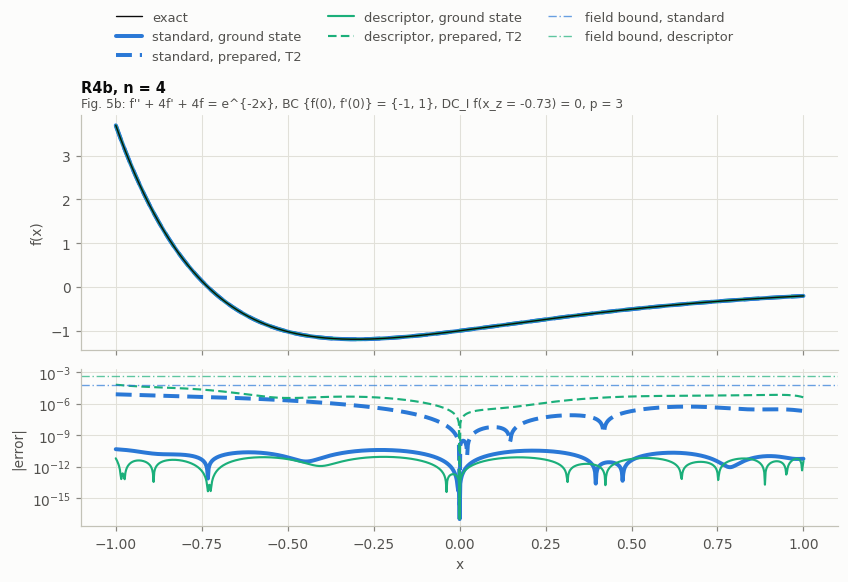

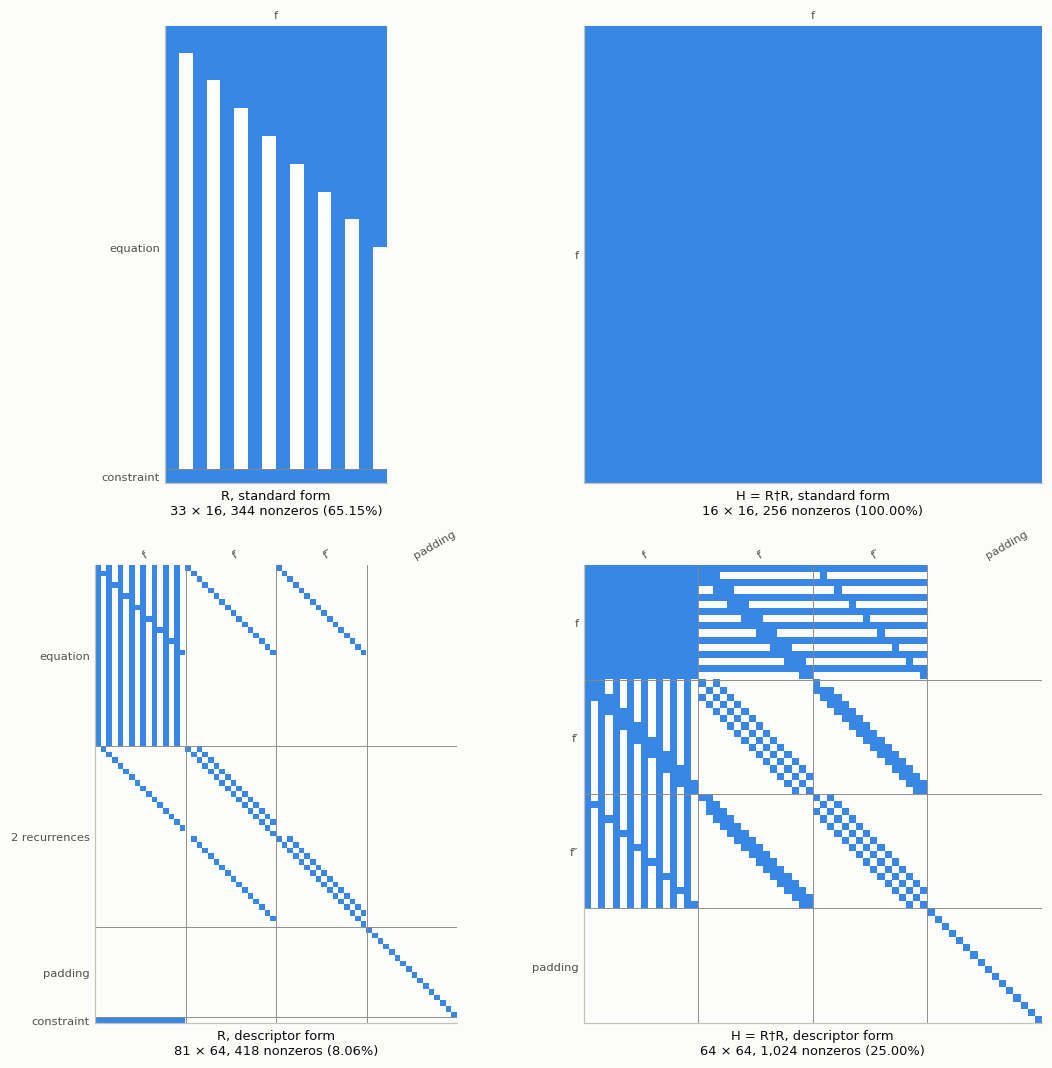

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 4 | 6 |
| state dimension | 16 | 64 |
| nonzeros of R | 344 | 418 |
| ‖H‖ | 1.39e+08 | 1.524e+04 |
| gap Δ | 5.882 | 3.45 |
| relative gap Δ/‖H‖ | 4.23e-08 | 0.000226 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 29.5 | 167.2 |
| ideal η_e = ‖b‖² | 29.5 | 167.2 |
| field error L∞ (ε_disc) | 4.61e-11 | 8.6e-12 |
| field error, relative L² | 1.88e-11 | 4.35e-12 |
| readout amplification | 7.56 | 18 |
| wall time (s) | 0.005587 | 0.126 |
| **encoding (Pillar 1)** | | |
| α_R | 8.285e+04 | 247 |
| system qubits | 4 | 6 |
| ancilla qubits | 13 | 14 |
| total qubits | 17 | 20 |
| CX gates | 24,930 | 37,542 |
| one-qubit gates | 28,448 | 41,322 |
| circuit depth | 42,092 | 69,806 |
| verification | probe | probe |
| verification error | 2.06e-15 | 2.92e-15 |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 247,819 | 965 |
| success (post-selection) probability | 0.2267 | 0.04001 |
| initial overlap γ² | 0.2267 | 0.04001 |
| infidelity | 2.97e-12 | 2.24e-11 |
| infidelity bound | 3.41e-12 | 2.38e-11 |
| distance from the ground state | 1.72e-06 | 4.73e-06 |
| field error L∞ | 7.92e-06 | 6.47e-05 |
| field bound | 6.11e-05 | 0.0004 |
| field within its bound | yes | yes |
| wall time (s) | 34.46 | 0.4984 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 247,819 | 965 |
| qubits | 18 | 21 |
| gates | 19,203,494,310 | 260,918,630 |
| predicted success probability | 0.2267 | 0.04001 |
| amplitude amplification rounds | 1 | 3 |
| preparations | 3 | 7 |
| beyond the simulation ceiling | no | no |

In [4]:
plotting.show_case(catalogue, catalogue.richest("R4b"));

### R5b, n = 4
Fig. 6d: heat, k = 1/25, IBC {f(0, x) = sin(2 pi x), f(t, ±1) = 0}, DC_I {f(t, ±1) = 0, f_x(t, ±3/4) = 0}; corrected: the solution imposed at t = -1, forward

| stage | form | run key |
|---|---|---|
| build | standard | `build/R5b/standard/n4x4` |
| build | descriptor | `build/R5b/descriptor/n4x4` |
| encoding | standard | `encode/R5b/standard/n4x4/verify=probe` |
| encoding | descriptor | `encode/R5b/descriptor/n4x4/verify=none` |
| T2 | standard | `stateprep/R5b/standard/n4x4/T2/filter=minimax` |
| T2 | descriptor | `stateprep/R5b/descriptor/n4x4/T2/filter=minimax` |
| T3 | standard | `stateprep/R5b/standard/n4x4/T3/filter=minimax` |
| T3 | descriptor | `stateprep/R5b/descriptor/n4x4/T3/filter=minimax` |

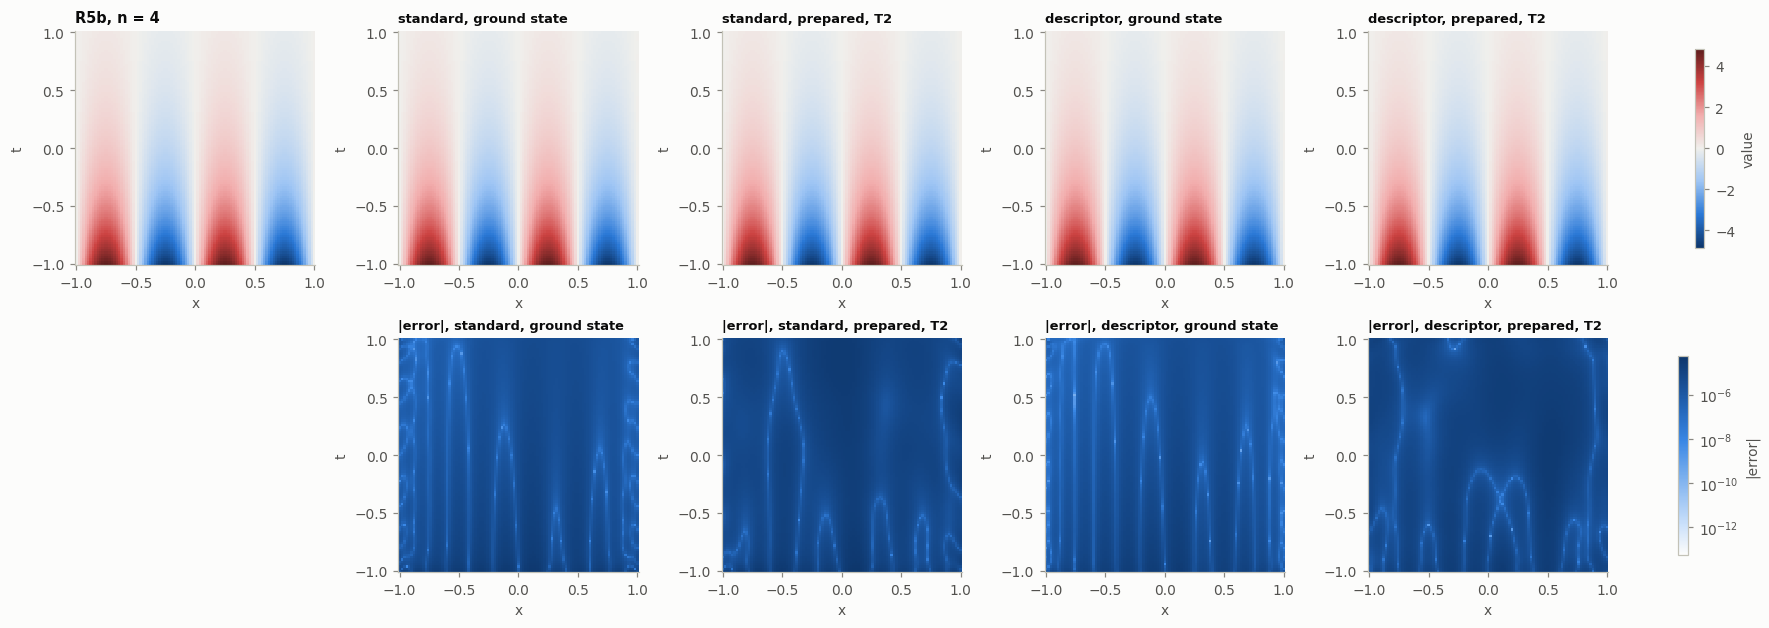

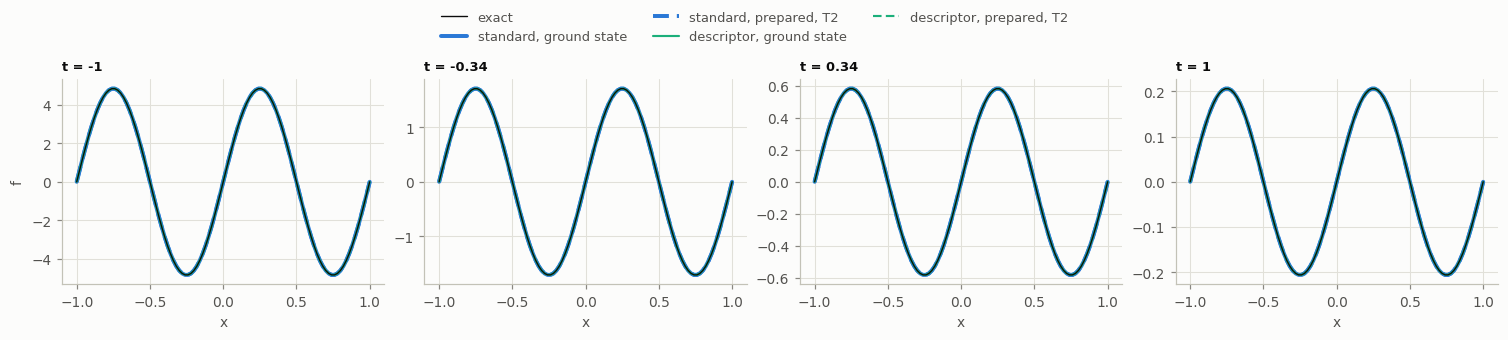

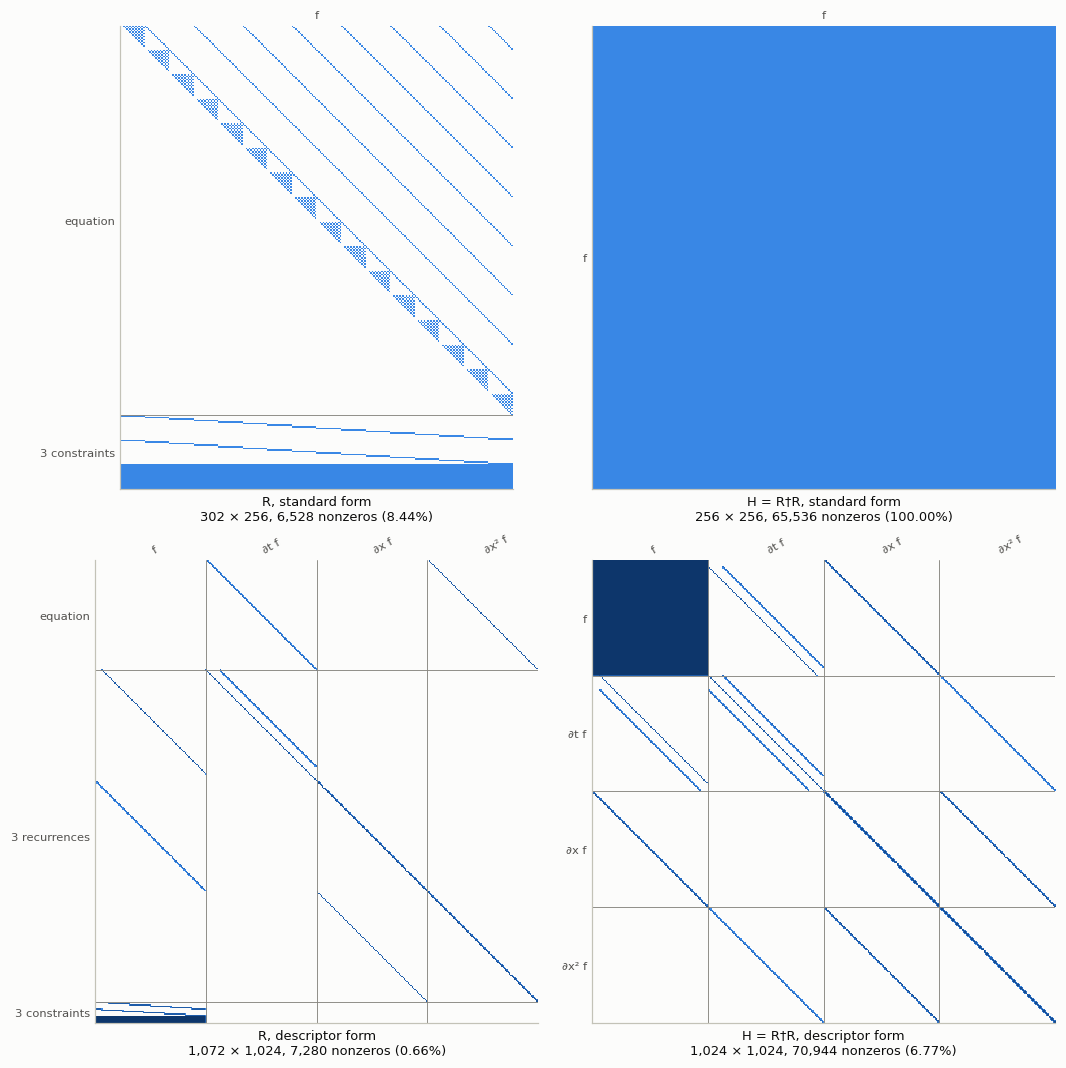

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 8 | 10 |
| state dimension | 256 | 1,024 |
| nonzeros of R | 6,528 | 7,280 |
| ‖H‖ | 1.36e+05 | 4.27e+05 |
| gap Δ | 0.4442 | 0.1393 |
| relative gap Δ/‖H‖ | 3.26e-06 | 3.26e-07 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 598.9 | 745.8 |
| ideal η_e = ‖b‖² | 598.9 | 745.8 |
| field error L∞ (ε_disc) | 4.68e-05 | 3.07e-05 |
| field error, relative L² | 4.64e-06 | 3.76e-06 |
| readout amplification | 47.41 | 52.91 |
| wall time (s) | 0.03895 | 0.4209 |
| **encoding (Pillar 1)** | | |
| α_R | 2544 | 1494 |
| system qubits | 8 | 10 |
| ancilla qubits | 12 | 19 |
| total qubits | 20 | 29 |
| CX gates | 24,596 | 68,858 |
| one-qubit gates | 27,982 | 74,214 |
| circuit depth | 40,478 | 129,165 |
| verification | probe | none |
| verification error | 2.78e-15 | – |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 27,692 | 29,044 |
| success (post-selection) probability | 0.01889 | 0.01517 |
| initial overlap γ² | 0.01889 | 0.01517 |
| infidelity | 3.23e-11 | 3.51e-11 |
| infidelity bound | 5.19e-11 | 6.49e-11 |
| distance from the ground state | 5.68e-06 | 5.93e-06 |
| field error L∞ | 5.77e-05 | 3.28e-05 |
| field bound | 0.000585 | 0.000657 |
| field within its bound | yes | yes |
| wall time (s) | 9.311 | 11.47 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 27,692 | 29,044 |
| qubits | 21 | 30 |
| gates | 7,715,212,736 | 26,846,124,344 |
| predicted success probability | 0.01889 | 0.01517 |
| amplitude amplification rounds | 5 | 6 |
| preparations | 11 | 13 |
| beyond the simulation ceiling | no | no |

In [5]:
plotting.show_case(catalogue, catalogue.richest("R5b"));

### R7, n = 7
u' = v, v' = -pi^2 u, (u, v)(-1) = (0, pi)

| stage | form | run key |
|---|---|---|
| build | standard | `build/R7/standard/n7` |
| build | descriptor | `build/R7/descriptor/n7` |
| T2 | standard | `stateprep/R7/standard/n7/T2/filter=minimax` |
| T2 | descriptor | `stateprep/R7/descriptor/n7/T2/filter=minimax` |
| T3 | standard | `stateprep/R7/standard/n7/T3/filter=minimax` |
| T3 | descriptor | `stateprep/R7/descriptor/n7/T3/filter=minimax` |

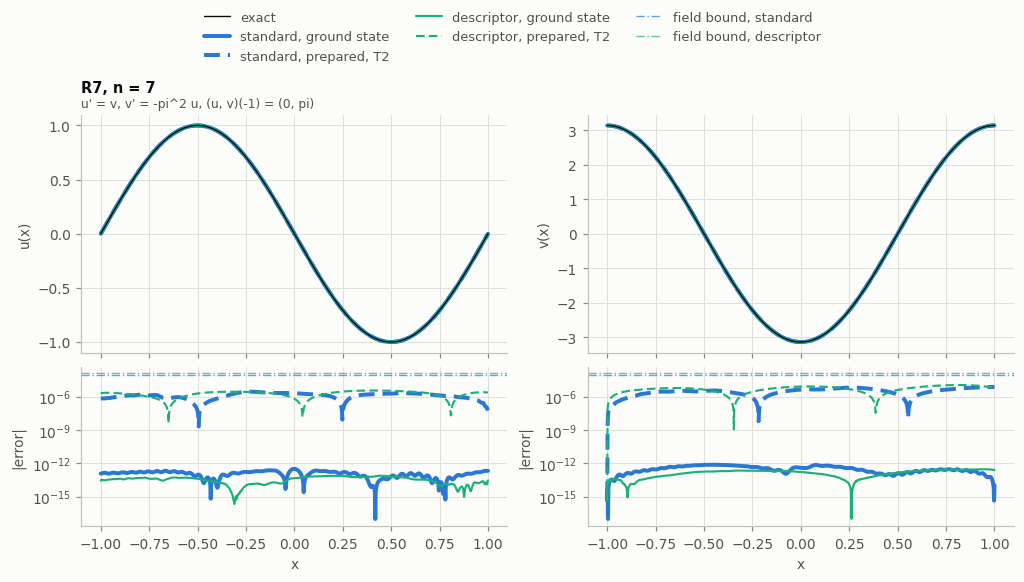

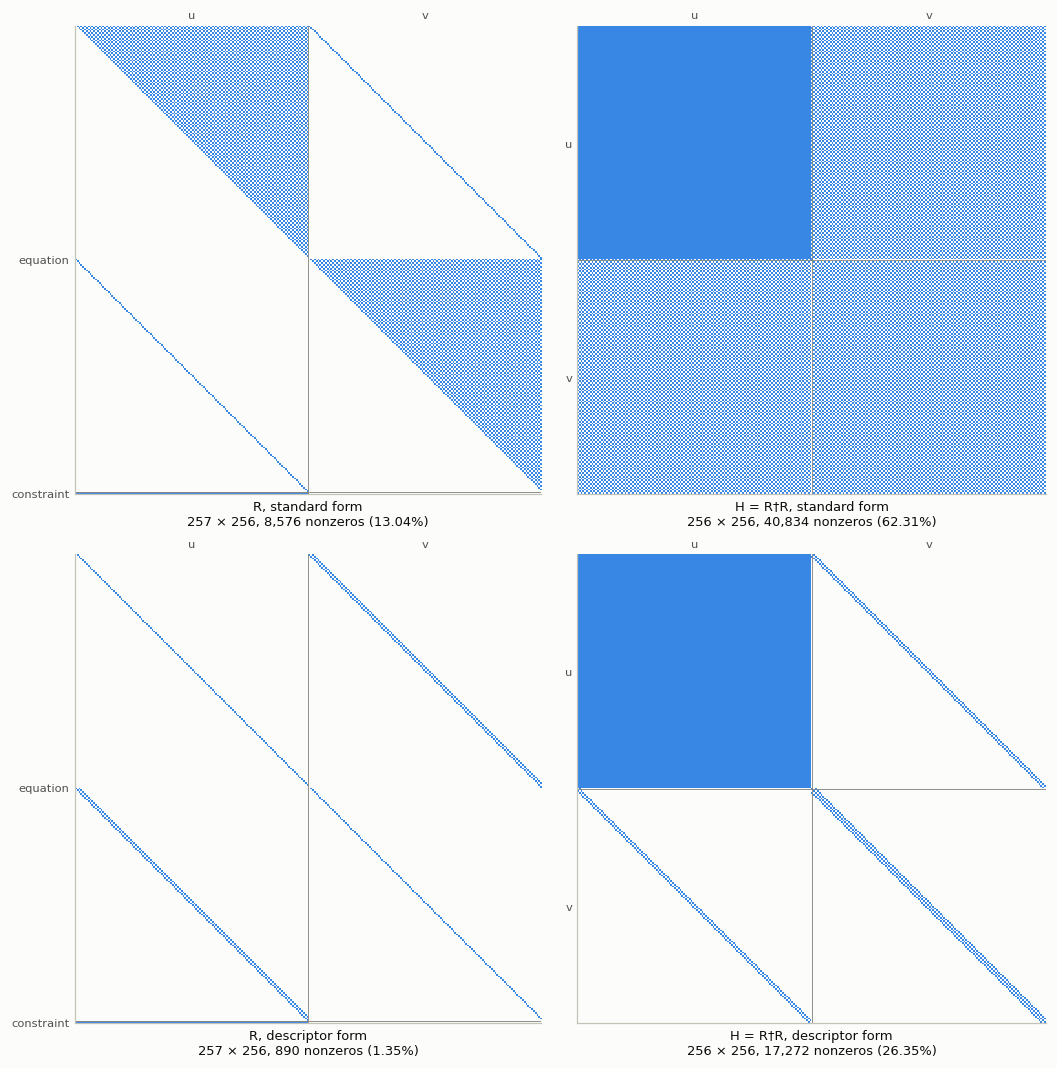

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 8 | 8 |
| state dimension | 256 | 256 |
| nonzeros of R | 8,576 | 890 |
| ‖H‖ | 5.99e+07 | 6.793e+04 |
| gap Δ | 0.1096 | 0.1321 |
| relative gap Δ/‖H‖ | 1.83e-09 | 1.94e-06 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 820.7 | 820.7 |
| ideal η_e = ‖b‖² | 820.7 | 820.7 |
| field error L∞ (ε_disc) | 7.57e-13 | 2.95e-13 |
| field error, relative L² | 1.81e-13 | 7.7e-14 |
| readout amplification | 40.43 | 40.43 |
| wall time (s) | 2.409 | 3.383 |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 356,379 | 5,794 |
| success (post-selection) probability | 0.2473 | 0.2473 |
| initial overlap γ² | 0.2473 | 0.2473 |
| infidelity | 1.38e-12 | 2.46e-12 |
| infidelity bound | 3.04e-12 | 3.04e-12 |
| distance from the ground state | 1.17e-06 | 1.57e-06 |
| field error L∞ | 7.31e-06 | 1.09e-05 |
| field bound | 9.5e-05 | 0.000127 |
| field within its bound | yes | yes |
| wall time (s) | 94.38 | 1.008 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 356,379 | 5,794 |
| qubits | 22 | 19 |
| gates | 10,404,841,284 | 317,638,668 |
| predicted success probability | 0.2473 | 0.2473 |
| amplitude amplification rounds | 1 | 1 |
| preparations | 3 | 3 |
| beyond the simulation ceiling | no | no |

In [6]:
plotting.show_case(catalogue, catalogue.richest("R7"));

### R8, n = 8, K = 6
y' = -y + y^2 on [0, 3], y(0) = 1/2, time on t = 2s/3 - 1

| stage | form | run key |
|---|---|---|
| build | standard | `build/R8/standard/n8/carleman=6` |
| build | descriptor | `build/R8/descriptor/n8/carleman=6` |
| T2 | standard | `stateprep/R8/standard/n8/T2/carleman=6/filter=minimax` |
| T2 | descriptor | `stateprep/R8/descriptor/n8/T2/carleman=6/filter=minimax` |
| T3 | standard | `stateprep/R8/standard/n8/T3/carleman=6/filter=minimax` |
| T3 | descriptor | `stateprep/R8/descriptor/n8/T3/carleman=6/filter=minimax` |

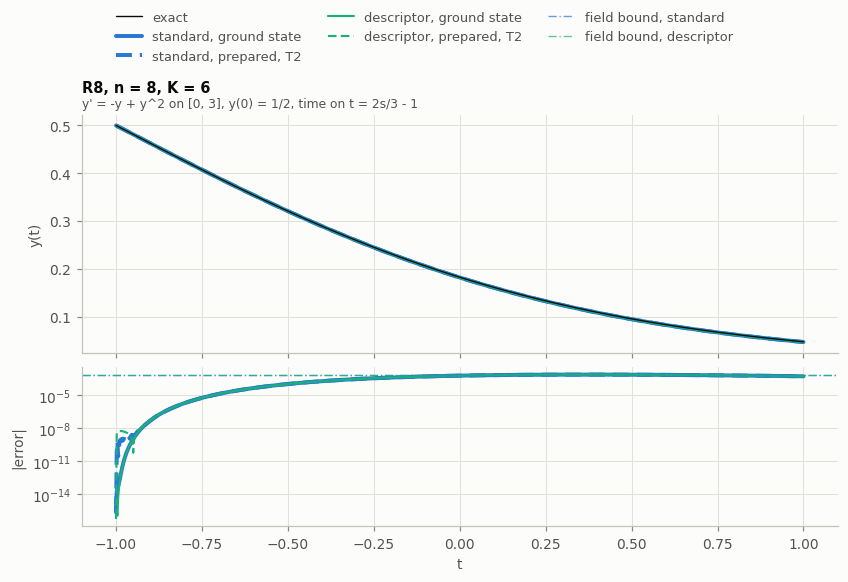

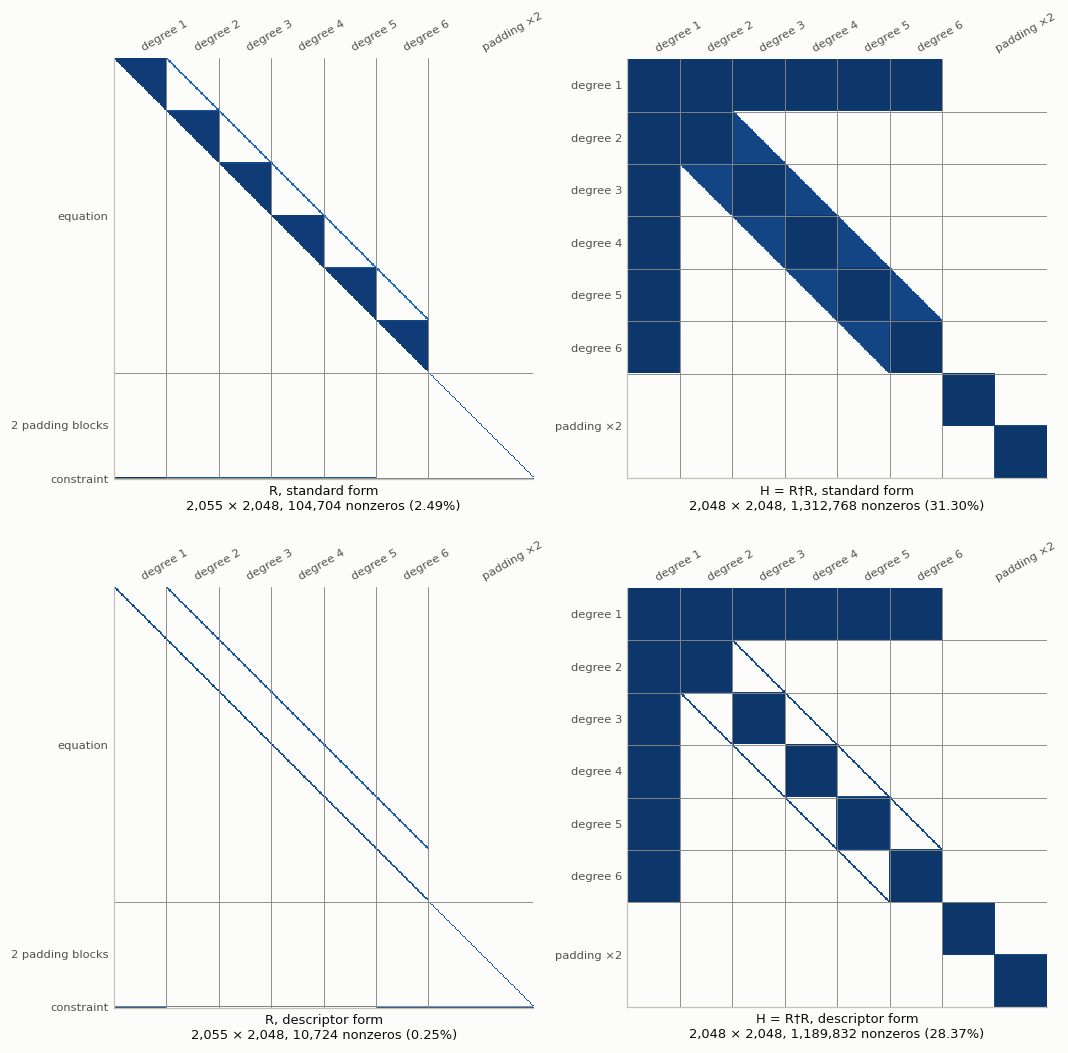

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 11 | 11 |
| state dimension | 2,048 | 2,048 |
| nonzeros of R | 104,704 | 10,724 |
| ‖H‖ | 9.58e+08 | 2.66e+05 |
| gap Δ | 1.967 | 3.489 |
| relative gap Δ/‖H‖ | 2.05e-09 | 1.31e-05 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 24.84 | 24.84 |
| ideal η_e = ‖b‖² | 24.88 | 24.88 |
| field error L∞ (ε_disc) | 0.00078 | 0.00078 |
| field error, relative L² | 0.002126 | 0.002126 |
| the lift's error L∞ | 0.00078 | 0.00078 |
| readout amplification | 7.041 | 7.041 |
| wall time (s) | 60.05 | 69 |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 506,586 | 3,207 |
| success (post-selection) probability | 0.7803 | 0.7803 |
| initial overlap γ² | 0.7803 | 0.7803 |
| infidelity | 1.8e-13 | 1.92e-13 |
| infidelity bound | 2.82e-13 | 2.8e-13 |
| distance from the ground state | 4.24e-07 | 4.37e-07 |
| field error L∞ | 0.000779 | 0.00078 |
| field bound | 0.000785 | 0.000786 |
| field within its bound | yes | yes |
| wall time (s) | 734.5 | 2.006 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 506,586 | 3,207 |
| qubits | 28 | 24 |
| gates | 10,250,261,124 | 137,605,956 |
| predicted success probability | 0.7803 | 0.7803 |
| amplitude amplification rounds | 0 | 0 |
| preparations | 1 | 1 |
| beyond the simulation ceiling | no | no |

In [7]:
plotting.show_case(catalogue, catalogue.richest("R8"));

### R9c-M8, n = 4, K = 3
viscous Burgers u_s + u u_x = nu u_xx, u(x, 0) = a sin x, a = 1, nu = 1, s in [0, 1], 8 sine modes

| stage | form | run key |
|---|---|---|
| build | standard | `build/R9c-M8/standard/n4/carleman=3` |
| build | descriptor | `build/R9c-M8/descriptor/n4/carleman=3` |
| encoding | standard | `encode/R9c-M8/standard/n4/carleman=3/verify=none` |
| encoding | descriptor | `encode/R9c-M8/descriptor/n4/carleman=3/verify=none` |
| T2 | standard | `stateprep/R9c-M8/standard/n4/T2/carleman=3/filter=minimax` |
| T2 | descriptor | `stateprep/R9c-M8/descriptor/n4/T2/carleman=3/filter=minimax` |
| T3 | standard | `stateprep/R9c-M8/standard/n4/T3/carleman=3/filter=minimax` |
| T3 | descriptor | `stateprep/R9c-M8/descriptor/n4/T3/carleman=3/filter=minimax` |
| coupling | symmetric | `lift/R9c-M8/standard/n0/carleman=3/verify=ir` |
| coupling | tensor | `lift/R9c-M8/standard/n0/carleman=3/lift=tensor/verify=ir` |

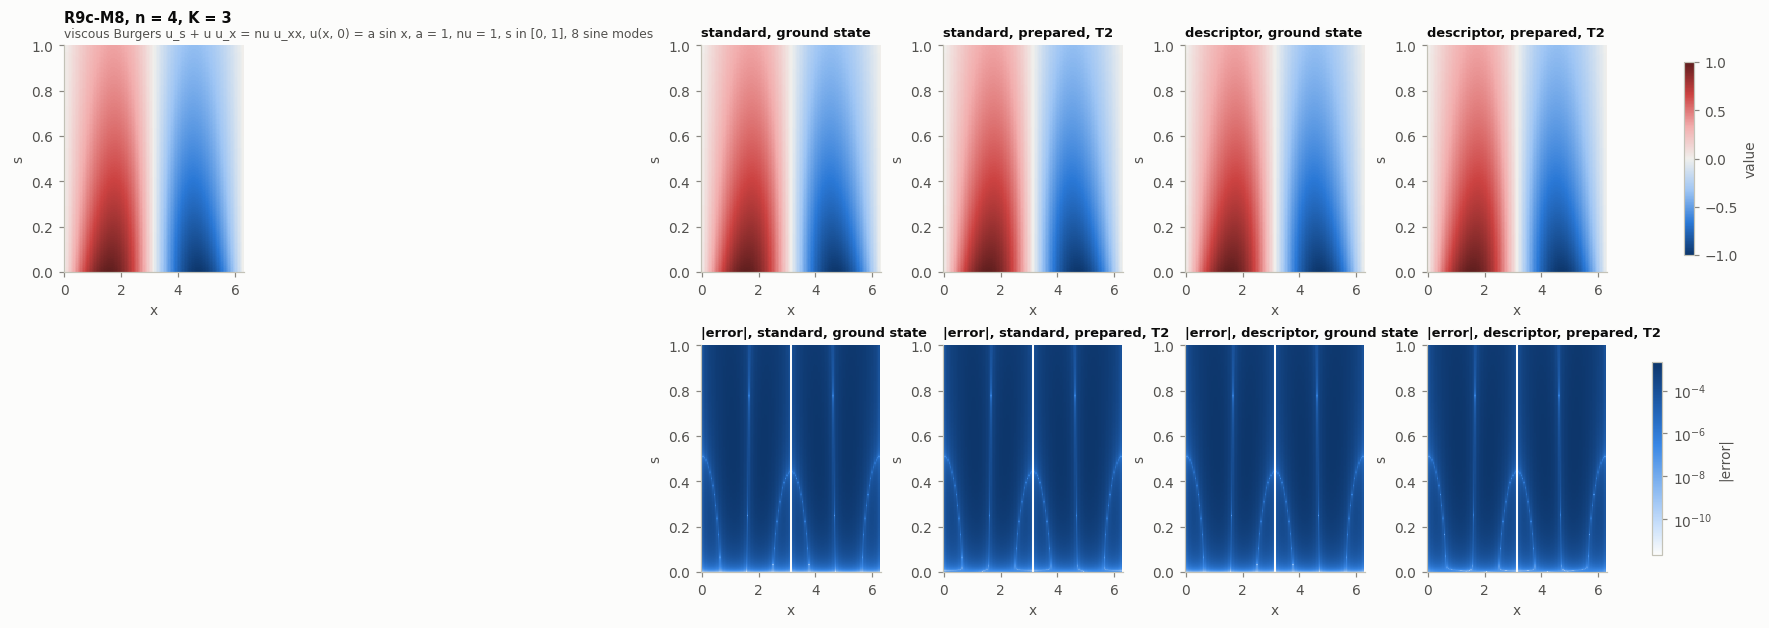

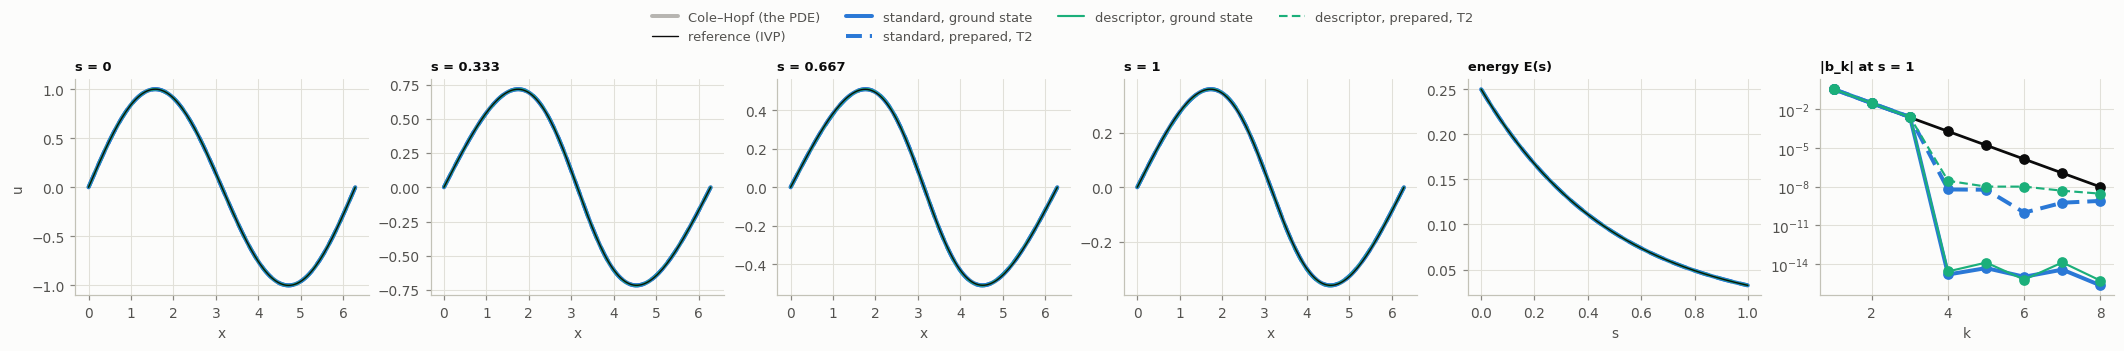

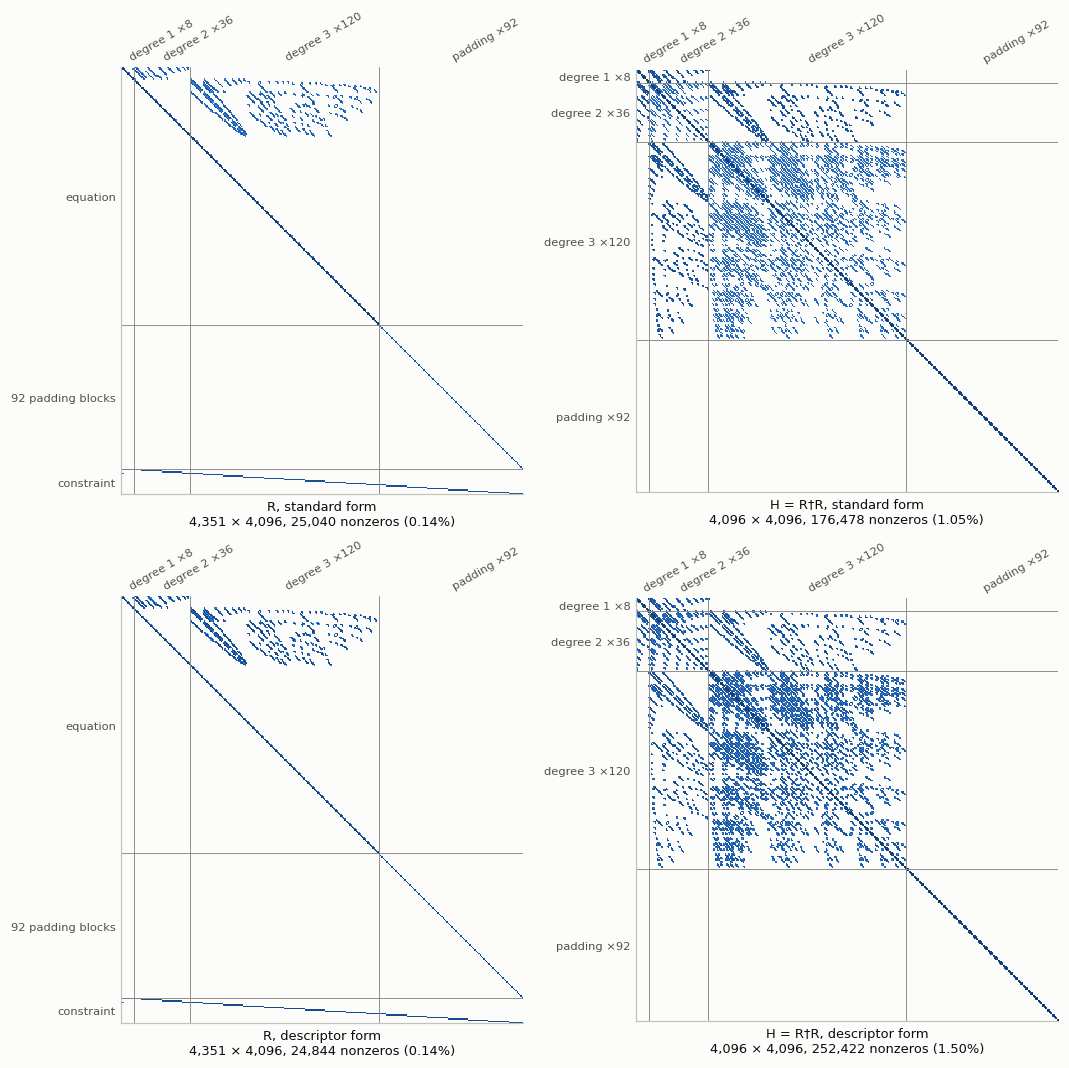

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 12 | 12 |
| state dimension | 4,096 | 4,096 |
| nonzeros of R | 25,040 | 24,844 |
| ‖H‖ | 3.637e+04 | 5.966e+04 |
| gap Δ | 1.125 | 2.694 |
| relative gap Δ/‖H‖ | 3.09e-05 | 4.52e-05 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 16.23 | 16.23 |
| ideal η_e = ‖b‖² | 16.14 | 16.14 |
| field error L∞ (ε_disc) | 0.001739 | 0.001739 |
| field error, relative L² | 0.002203 | 0.002203 |
| the lift's error L∞ | 0.001739 | 0.001739 |
| readout amplification | 5.607 | 5.607 |
| wall time (s) | 13.73 | 5.151 |
| **encoding (Pillar 1)** | | |
| α_R | 748.7 | 512.8 |
| system qubits | 12 | 12 |
| ancilla qubits | 16 | 15 |
| total qubits | 28 | 27 |
| CX gates | 369,596 | 725,890 |
| one-qubit gates | 414,939 | 811,316 |
| circuit depth | 631,073 | 1,236,365 |
| verification | none | none |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 5,121 | 2,267 |
| success (post-selection) probability | 0.4261 | 0.4261 |
| initial overlap γ² | 0.4261 | 0.4261 |
| infidelity | 9.05e-13 | 5.67e-13 |
| infidelity bound | 1.34e-12 | 1.34e-12 |
| distance from the ground state | 9.52e-07 | 7.53e-07 |
| field error L∞ | 0.001739 | 0.001739 |
| field bound | 0.00175 | 0.001747 |
| field within its bound | yes | yes |
| wall time (s) | 8.182 | 12.18 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 5,121 | 2,267 |
| qubits | 29 | 28 |
| gates | 5,701,147,848 | 4,945,510,374 |
| predicted success probability | 0.4261 | 0.4261 |
| amplitude amplification rounds | 1 | 1 |
| preparations | 3 | 3 |
| beyond the simulation ceiling | no | no |

| | symmetric | tensor |
|---|---|---|
| **the coupling's circuit** | | |
| components | 164 | 4,368 |
| terms | 15 | 5 |
| α | 126 | 112 |
| α/‖𝔸_K‖ | 1.312 | 1.167 |
| total qubits | 13 | 28 |
| ancilla qubits | 5 | 11 |
| CX gates | 51,714 | 11,718 |
| circuit depth | 88,910 | 18,939 |
| verification | ir | ir |
| verification error | 0 | 0 |

In [8]:
plotting.show_case(catalogue, catalogue.richest("R9c-M8"));

### R10c-M12, n = 4, K = 4
2-D Navier-Stokes from a counter-rotating vortex pair of norm a = 10, nu = 1, s in [0, 1], |k|^2 <= 4

| stage | form | run key |
|---|---|---|
| build | standard | `build/R10c-M12/standard/n4/carleman=4` |
| build | descriptor | `build/R10c-M12/descriptor/n4/carleman=4` |
| T2 | standard | `stateprep/R10c-M12/standard/n4/T2/carleman=4/filter=minimax` |
| T2 | descriptor | `stateprep/R10c-M12/descriptor/n4/T2/carleman=4/filter=minimax` |
| T3 | standard | `stateprep/R10c-M12/standard/n4/T3/carleman=4/filter=minimax` |
| T3 | descriptor | `stateprep/R10c-M12/descriptor/n4/T3/carleman=4/filter=minimax` |
| coupling | tensor | `lift/R10c-M12/standard/n0/carleman=4/lift=tensor/verify=ir` |

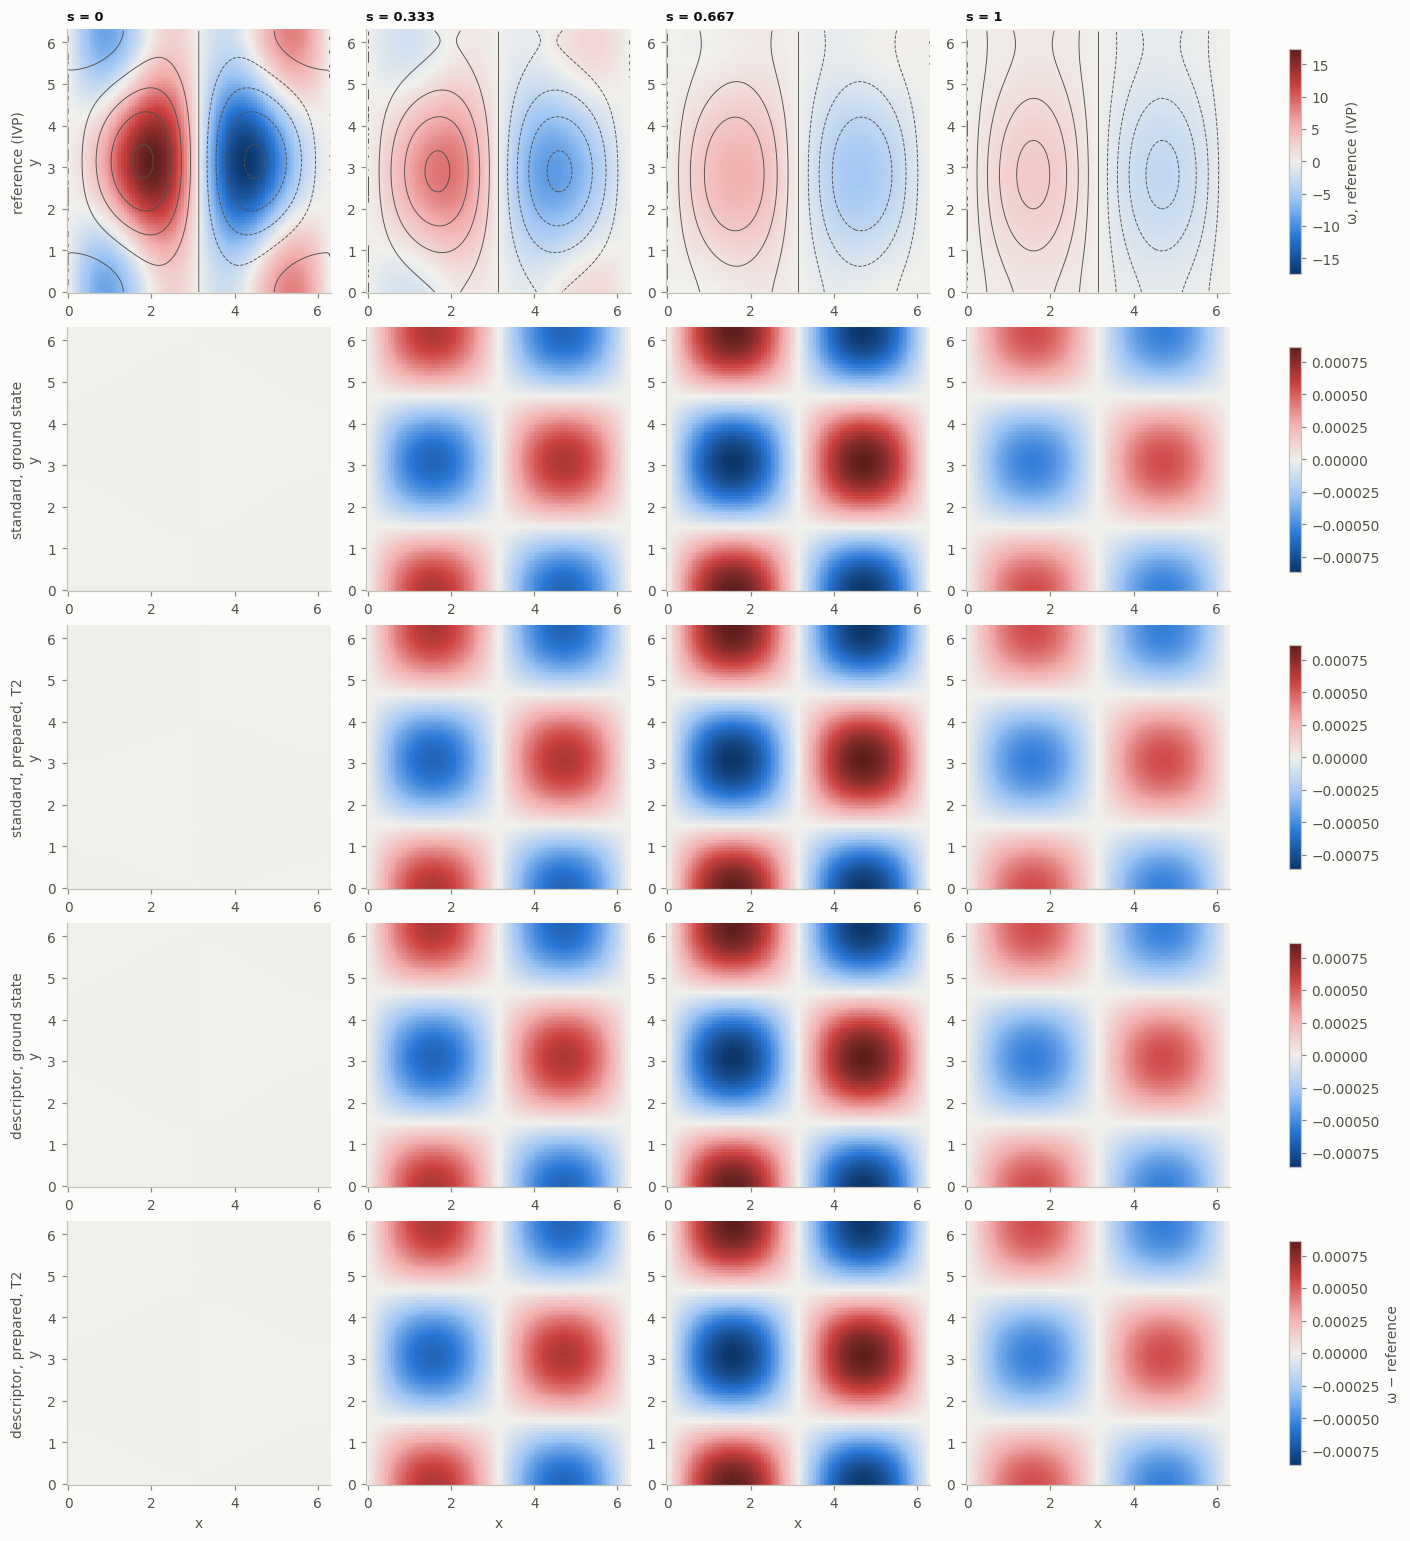

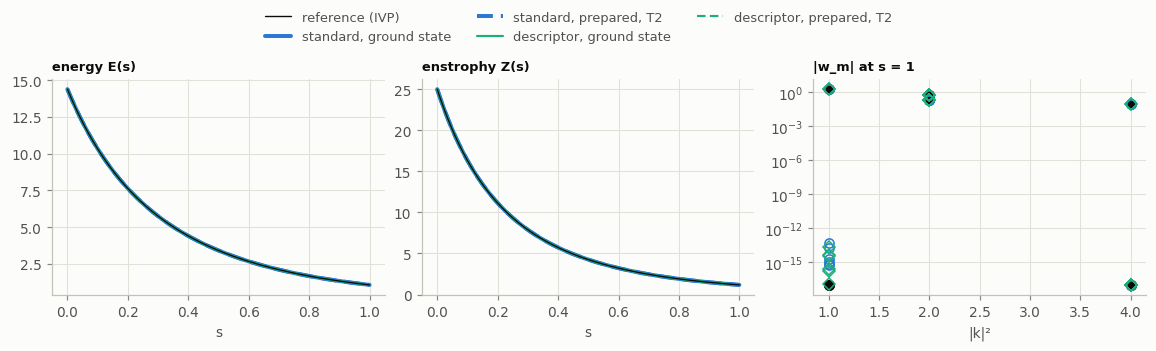

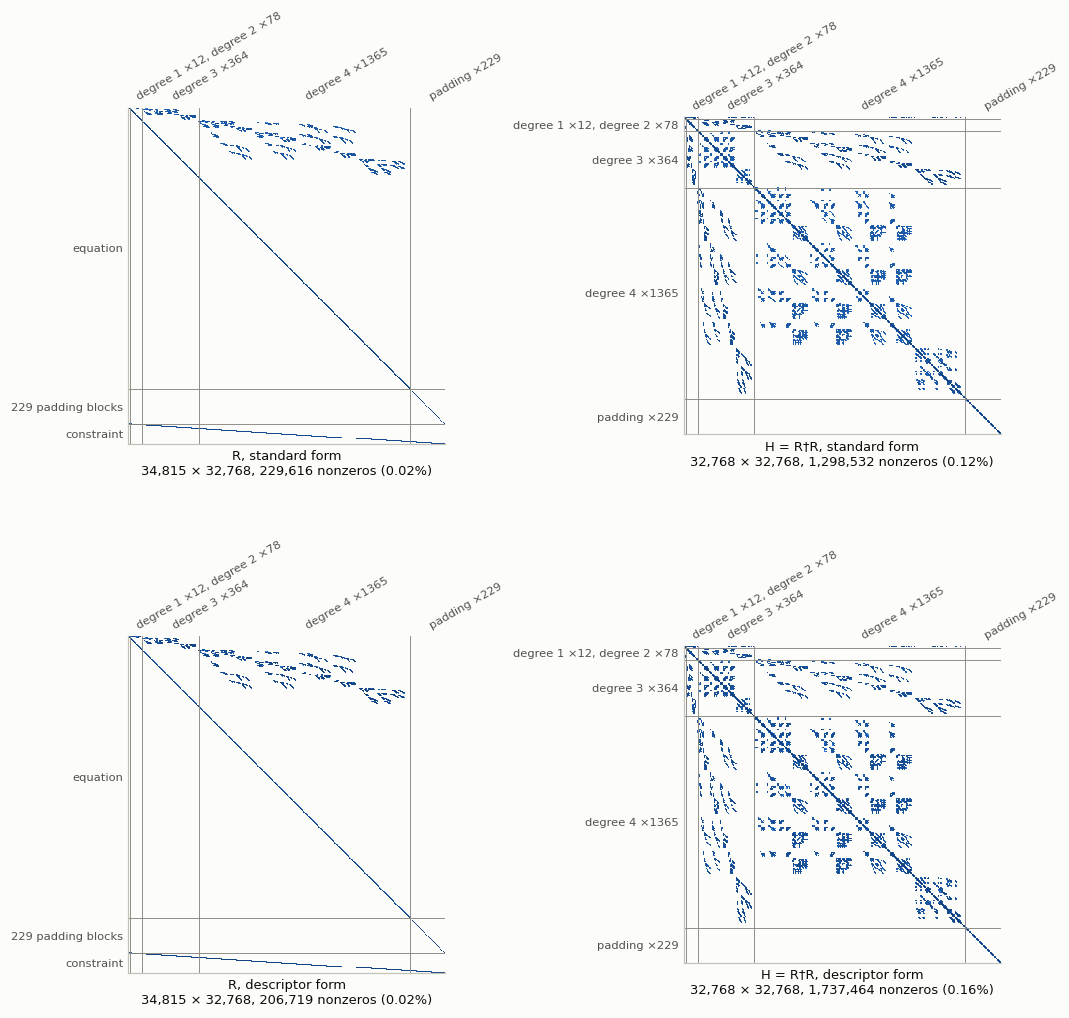

| | standard | descriptor |
|---|---|---|
| **classical build** | | |
| state qubits | 15 | 15 |
| state dimension | 32,768 | 32,768 |
| nonzeros of R | 229,616 | 206,719 |
| ‖H‖ | 1.508e+04 | 1373 |
| gap Δ | 0.05583 | 0.1084 |
| relative gap Δ/‖H‖ | 3.7e-06 | 7.89e-05 |
| kernel dimension | 1 | 1 |
| ground state trusted | yes | yes |
| η_e | 846.7 | 846.7 |
| ideal η_e = ‖b‖² | 8.461 | 8.461 |
| field error L∞ (ε_disc) | 0.000453 | 0.000453 |
| field error, relative L² | 9.15e-05 | 9.15e-05 |
| the lift's error L∞ | 0.000453 | 0.000453 |
| readout amplification | 40.5 | 40.5 |
| wall time (s) | 9.288 | 8.657 |
| **preparation, T2 (exact emulation)** | | |
| filter | minimax | minimax |
| filter degree | 30,825 | 6,052 |
| success (post-selection) probability | 0.5636 | 0.5636 |
| initial overlap γ² | 0.5636 | 0.5636 |
| infidelity | 3.47e-13 | 3.96e-13 |
| infidelity bound | 7.74e-13 | 7.73e-13 |
| distance from the ground state | 5.9e-07 | 6.29e-07 |
| field error L∞ | 0.000453 | 0.000452 |
| field bound | 0.0005 | 0.000504 |
| field within its bound | yes | yes |
| wall time (s) | 6117 | 6463 |
| **estimate, T3** | | |
| status | ok | ok |
| filter | minimax | minimax |
| filter degree | 30,825 | 6,052 |
| qubits | 37 | 36 |
| gates | 849,430,345,500 | 445,451,843,744 |
| predicted success probability | 0.5636 | 0.5636 |
| amplitude amplification rounds | 0 | 0 |
| preparations | 1 | 1 |
| beyond the simulation ceiling | no | no |

| | tensor |
|---|---|
| **the coupling's circuit** | |
| components | 22,620 |
| terms | 7 |
| α | 347.4 |
| α/‖𝔸_K‖ | 20.28 |
| total qubits | 42 |
| ancilla qubits | 15 |
| CX gates | 133,910 |
| circuit depth | 223,448 |
| verification | ir |
| verification error | 0 |

In [9]:
plotting.show_case(catalogue, catalogue.richest("R10c-M12"));

**What this does not show.** The protocol and filter studies (notebooks 33 and 34), which
compare choices rather than show a case. The equation's own solution beyond R9's Cole–Hopf: R10's
truncation error against its simulation is notebook 70's. A preparation whose record kept no
field is judged here by its metrics alone.